# 💳 Taller de Clustering — Parte 2: Tarjetas de crédito

Notebook de trabajo: solo contiene las fases ya vistas (ver [`learn_roadmap.md`](learn_roadmap.md)).

## ✅ Fase 07 · Comprensión del problema y de los datos — ya vista

> **Resumen fase 07:** **8.950 clientes × 18 columnas**, todas **numéricas** salvo `CUST_ID` (una **matrícula**: un valor distinto por cliente, no sirve para agrupar). **No hay etiqueta**. Escalas **muy distintas** (0–1 frente a miles) y **colas largas** (media ≫ mediana). Nulos: `CREDIT_LIMIT` (**1**) y `MINIMUM_PAYMENTS` (**313**). Búsqueda sistemática: 0 negativos y **8 frecuencias > 1** (imposibles).

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook
import warnings
warnings.filterwarnings("ignore")  # oculta avisos para que la salida quede limpia

import pandas as pd              # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np               # cálculo numérico
import seaborn as sns            # gráficos estadísticos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semilla fija: así los resultados se pueden repetir

df = pd.read_csv("docs/workshop/data/credit_card.csv")
df.head()

# ¿Cuántos clientes (filas) y cuántas variables (columnas)?
df.shape

# Tipos de datos: ¿hay texto o todo es número?
print(df.dtypes.value_counts())
df.dtypes

print("Valores distintos en CUST_ID:", df["CUST_ID"].nunique(), "de", len(df), "filas")
df["CUST_ID"].head()

# .T gira la tabla: una fila por variable, más fácil de leer
df.describe().T.round(2)

numericas = df.drop(columns="CUST_ID")
print("Valores negativos en todo el dataset:", (numericas < 0).sum().sum())

frecuencias = [c for c in df.columns if c.endswith("_FREQUENCY")]
print("\nFrecuencias mayores que 1:")
print((df[frecuencias] > 1).sum())

# ¿Quiénes son esos clientes con frecuencia > 1?
df.loc[df["CASH_ADVANCE_FREQUENCY"] > 1,
       ["CUST_ID", "CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE_TRX", "TENURE"]]

# Nulos por columna (solo las que tengan alguno)
nulos = df.isnull().sum()
nulos[nulos > 0]

float64    14
int64       3
str         1
Name: count, dtype: int64
Valores distintos en CUST_ID: 8950 de 8950 filas
Valores negativos en todo el dataset: 0

Frecuencias mayores que 1:
BALANCE_FREQUENCY                   0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              8
dtype: int64


CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

## ✅ Fase 08 · Preparación de los datos — ya vista

> **Resumen fase 08:** quitamos `CUST_ID`, **recortamos a 1** las 8 frecuencias imposibles y rellenamos los nulos con la **mediana** (no se deja arrastrar por los extremos: en `MINIMUM_PAYMENTS` media 864 vs mediana 312). Las variables de dinero tienen **colas largas**. Con **`StandardScaler`** todas quedan con **media 0 y desviación 1**: antes, unas pocas variables grandes decidían casi toda la distancia; después, todas pesan.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

Frecuencias > 1 tras corregir: 0
CREDIT_LIMIT       media:   4494.4   mediana:   3000.0   máximo:   30000.0
MINIMUM_PAYMENTS   media:    864.2   mediana:    312.3   máximo:   76406.2
Nulos que quedan: 0


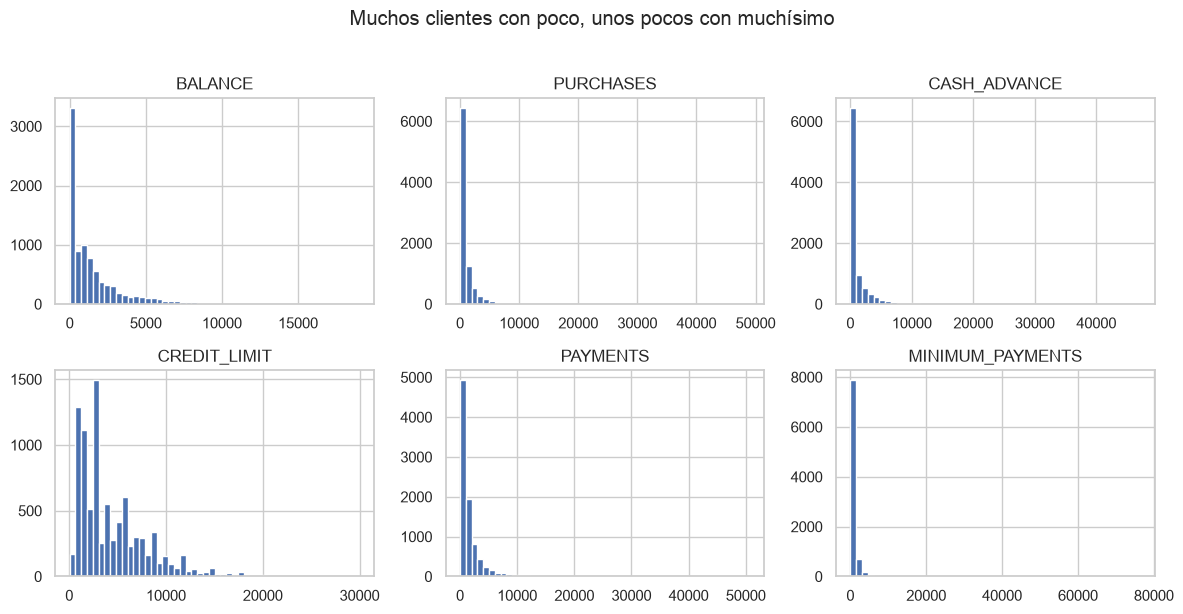

,% sin escalar,% escalado
CREDIT_LIMIT,39.8,8.3
BALANCE,15.4,6.8
PAYMENTS,13.3,3.4
CASH_ADVANCE,11.2,4.5
PURCHASES,7.7,2.5
MINIMUM_PAYMENTS,5.4,2.4
ONEOFF_PURCHASES,4.2,2.6
INSTALLMENTS_PURCHASES,3.0,3.5
PURCHASES_TRX,0.0,3.7
PRC_FULL_PAYMENT,0.0,8.3


In [2]:
df = df.drop(columns="CUST_ID")
df.shape

df["CASH_ADVANCE_FREQUENCY"] = df["CASH_ADVANCE_FREQUENCY"].clip(upper=1)
print("Frecuencias > 1 tras corregir:", (df["CASH_ADVANCE_FREQUENCY"] > 1).sum())

for col in ["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]:
    print(f"{col:17}  media: {df[col].mean():8.1f}   mediana: {df[col].median():8.1f}   máximo: {df[col].max():9.1f}")

for col in ["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]:
    df[col] = df[col].fillna(df[col].median())

print("Nulos que quedan:", df.isnull().sum().sum())

cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]
df[cols].hist(bins=50, figsize=(12, 6), layout=(2, 3))
plt.suptitle("Muchos clientes con poco, unos pocos con muchísimo", y=1.02)
plt.tight_layout(); plt.show()

# Asimetría (skew): 0 = simétrica; cuanto más alta, más larga la cola derecha
df.skew().sort_values(ascending=False).round(1).head(6)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df)                # array escalado: lo usaremos en todas las fases siguientes
X_df = pd.DataFrame(X, columns=df.columns)

# Comprobación: media 0 y desviación 1 en todas las columnas
X_df.agg(["mean", "std"]).T.round(2).head(6)

rng = np.random.default_rng(RANDOM_STATE)
i, j = rng.integers(0, len(df), 2000), rng.integers(0, len(df), 2000)   # 2000 parejas al azar

def aporte_por_variable(datos):
    d2 = (datos[i] - datos[j]) ** 2                          # lo que suma cada variable a la distancia²
    return (d2 / d2.sum(axis=1, keepdims=True)).mean(axis=0) * 100

pd.DataFrame({"% sin escalar": aporte_por_variable(df.values),
              "% escalado": aporte_por_variable(X)},
             index=df.columns).round(1).sort_values("% sin escalar", ascending=False)

## ✅ Fase 09 · Exploración: ¿se ven grupos? — ya vista

> **Resumen fase 09:** PC1 guarda el 27 % y PC2 el 20 %; para el **80 %** hacen falta **7 de 17** componentes, sin codo claro. **PC1 = compras** y **PC2 = efectivo/saldo**. En 2D se ve **una nube continua** con brazos, **sin grupos separados**: los segmentos serán **zonas** de la nube, no islas.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

Componentes para el 80 % de la varianza: 7 de 17


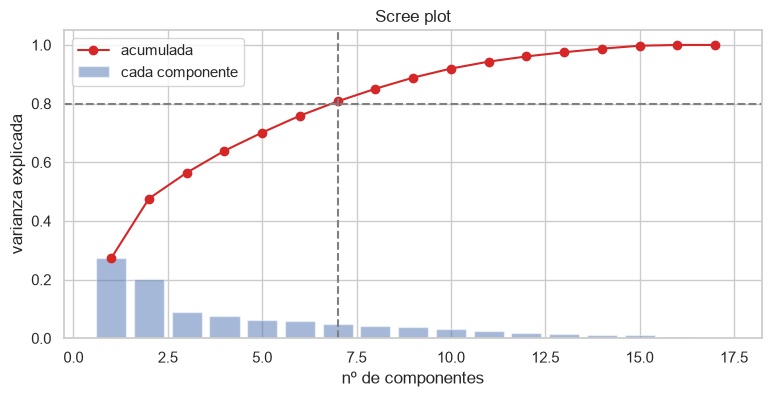

PC1: {'PURCHASES': 0.41, 'PURCHASES_TRX': 0.39, 'ONEOFF_PURCHASES': 0.35, 'INSTALLMENTS_PURCHASES': 0.34, 'PURCHASES_FREQUENCY': 0.32} 

PC2: {'CASH_ADVANCE': 0.44, 'CASH_ADVANCE_FREQUENCY': 0.43, 'CASH_ADVANCE_TRX': 0.42, 'BALANCE': 0.4, 'PAYMENTS': 0.26} 



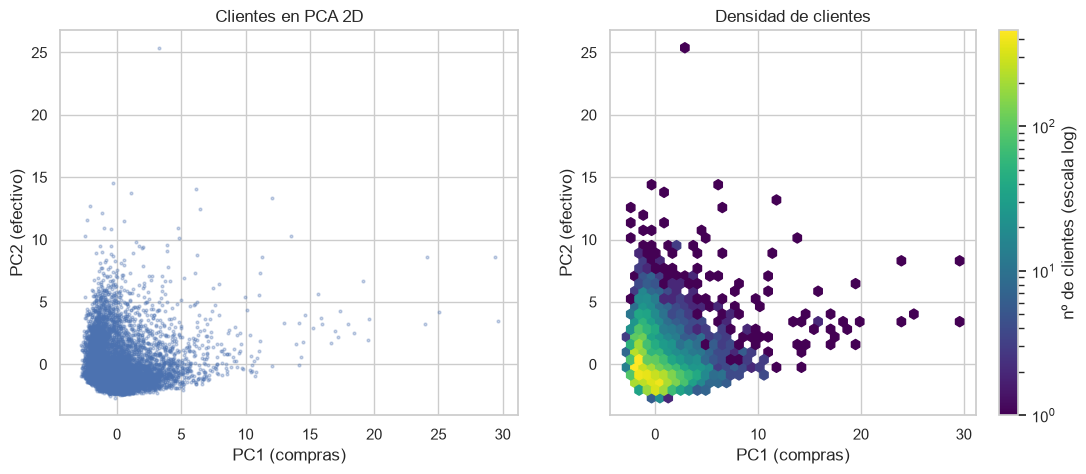

In [3]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=RANDOM_STATE).fit(X)
varianza = pca_full.explained_variance_ratio_
acumulada = varianza.cumsum()

n80 = np.argmax(acumulada >= 0.80) + 1        # primera componente que llega al 80 %
print(f"Componentes para el 80 % de la varianza: {n80} de {X.shape[1]}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, len(varianza) + 1), varianza, alpha=0.5, label="cada componente")
ax.plot(range(1, len(acumulada) + 1), acumulada, "o-", color="tab:red", label="acumulada")
ax.axhline(0.80, ls="--", color="gray"); ax.axvline(n80, ls="--", color="gray")
ax.set(xlabel="nº de componentes", ylabel="varianza explicada", title="Scree plot")
ax.legend(); plt.show()

pd.DataFrame({"varianza": varianza, "acumulada": acumulada},
             index=range(1, len(varianza) + 1)).round(3).head(8)

pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
X_pca = pca2.transform(X)

for k in range(2):
    pesos = pd.Series(pca2.components_[k], index=df.columns)
    top = pesos.reindex(pesos.abs().sort_values(ascending=False).index).head(5).round(2)
    print(f"PC{k+1}:", top.to_dict(), "\n")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: cada cliente un punto (sin colores: no hay etiqueta)
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], s=4, alpha=0.3)
ax[0].set(title="Clientes en PCA 2D", xlabel="PC1 (compras)", ylabel="PC2 (efectivo)")

# Derecha: densidad (hexágonos): ¿dónde se amontonan?
hb = ax[1].hexbin(X_pca[:, 0], X_pca[:, 1], gridsize=40, bins="log", cmap="viridis")
ax[1].set(title="Densidad de clientes", xlabel="PC1 (compras)", ylabel="PC2 (efectivo)")
fig.colorbar(hb, ax=ax[1], label="nº de clientes (escala log)")
plt.show()

## ✅ Fase 10 · Modelado: cortar la nube en segmentos — ya vista

> **Resumen fase 10:** con `X` (17 variables escaladas), la **silueta máxima** está en **k = 3** (≈ 0,24, baja por ser una nube continua); con k ≥ 5 aparecen grupos de ~86 clientes extremos. **K-Means k = 3**: ~68 % / ~18 % / ~14 %. **Aglomerativo** también da un grupo grande y uno de ~1.200, aunque no idénticos; **GMM** muy distinto (campanas sobre colas largas). **DBSCAN** ve **1 grupo + ruido**: no hay huecos en la nube.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

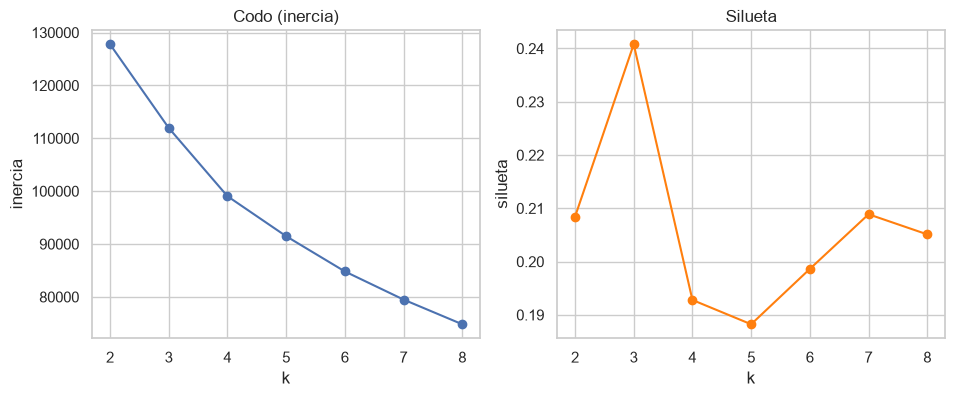

Mejor k por silueta: 3


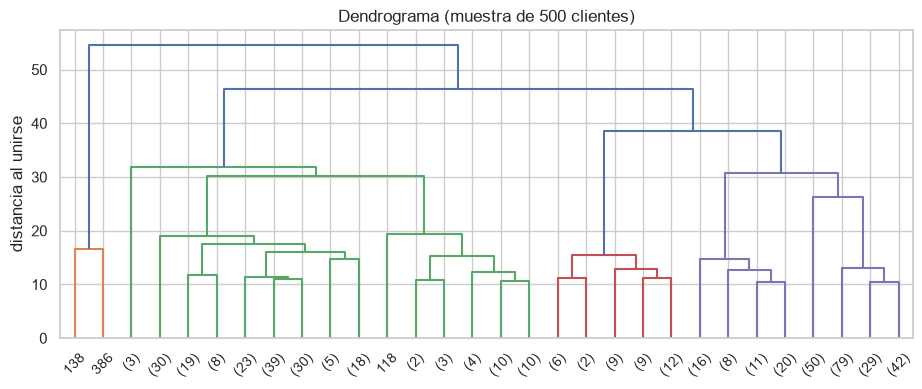

0    2606
1    2934
2    3410
Name: count, dtype: int64
Clientes con duda (ningún grupo > 90 %): 81
eps=0.1  -> grupos:  25   ruido:  2632   grupo mayor: 5918 clientes
eps=0.2  -> grupos:  13   ruido:   966   grupo mayor: 7844 clientes
eps=0.3  -> grupos:   4   ruido:   483   grupo mayor: 8426 clientes
eps=0.5  -> grupos:   3   ruido:   247   grupo mayor: 8682 clientes


eps=1.0  -> grupos:   1   ruido:    81   grupo mayor: 8869 clientes


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inercias, siluetas, tamaños = [], [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_, sample_size=4000, random_state=RANDOM_STATE))
    tamaños.append(sorted(np.bincount(km.labels_), reverse=True))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_values, inercias, "o-"); ax[0].set(title="Codo (inercia)", xlabel="k", ylabel="inercia")
ax[1].plot(k_values, siluetas, "o-", color="tab:orange"); ax[1].set(title="Silueta", xlabel="k", ylabel="silueta")
plt.show()

best_k = list(k_values)[int(np.argmax(siluetas))]
print("Mejor k por silueta:", best_k)
pd.DataFrame({"k": k_values, "inercia": inercias, "silueta": siluetas, "tamaños": tamaños}).round(3)

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X)
clusters_km = kmeans.labels_

tam = pd.Series(clusters_km).value_counts().sort_index()
pd.DataFrame({"clientes": tam, "%": (tam / len(X) * 100).round(1)})

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

rng = np.random.default_rng(RANDOM_STATE)
muestra = X[rng.choice(len(X), size=500, replace=False)]

plt.figure(figsize=(11, 4))
dendrogram(linkage(muestra, method="ward"), truncate_mode="lastp", p=30)
plt.title("Dendrograma (muestra de 500 clientes)"); plt.ylabel("distancia al unirse")
plt.show()

clusters_ag = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
pd.Series(clusters_ag).value_counts().sort_index()

from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=RANDOM_STATE).fit(X)
clusters_gmm = gmm.predict(X)
probs = gmm.predict_proba(X)

print(pd.Series(clusters_gmm).value_counts().sort_index())
print("Clientes con duda (ningún grupo > 90 %):", (probs.max(axis=1) < 0.9).sum())

from sklearn.cluster import DBSCAN

for eps in [0.1, 0.2, 0.3, 0.5, 1.0]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_pca)
    n_grupos = len(set(labels)) - (1 if -1 in labels else 0)
    mayor = np.bincount(labels[labels >= 0]).max()
    print(f"eps={eps:<4} -> grupos: {n_grupos:3d}   ruido: {(labels == -1).sum():5d}   grupo mayor: {mayor} clientes")

## ✅ Fase 11 · Evaluación sin etiqueta — ya vista

> **Resumen fase 11:** sin etiqueta **no hay ARI con la verdad**, pero sí podemos: (1) **métricas internas** → K-Means k = 3 gana (silueta **0,241**); ojo, **DBSCAN saca 0,719 con 1 grupo + 81 de ruido**: las métricas se engañan; (2) **ARI entre algoritmos** → coinciden poco (0,07–0,36): en una nube cada uno corta por un sitio; (3) **estabilidad** → K-Means estable, GMM no tanto; (4) **silueta por segmento** → el grande es sólido, los dos pequeños frágiles; (5) **t-SNE** → cada segmento en su zona, con bordes que se tocan.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

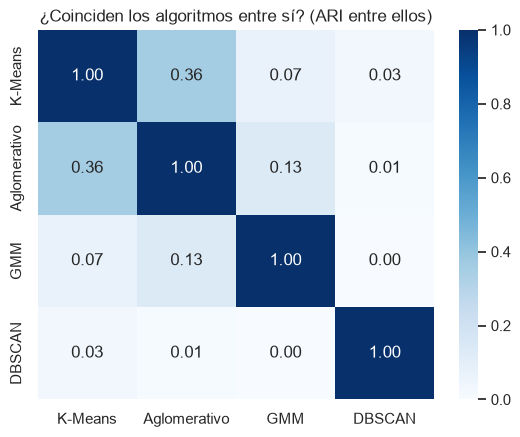

K-Means: ARI frente a la semilla 0 -> [1.0, 1.0, 1.0, 1.0, 0.98]
GMM:     ARI frente a la semilla 0 -> [1.0, 0.98, 0.8, 1.0, 1.0]


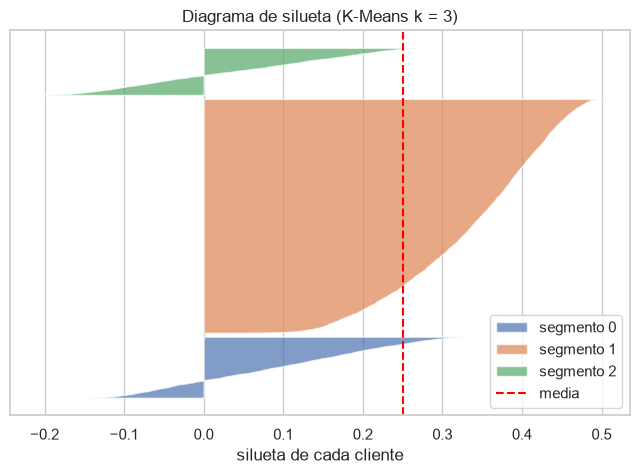

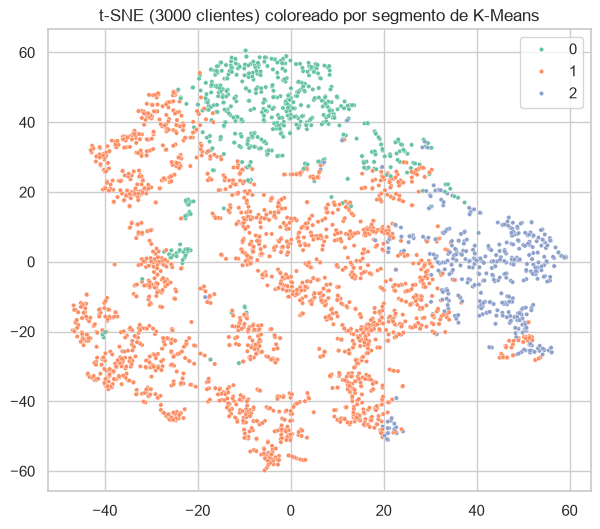

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import DBSCAN

clusters_db = DBSCAN(eps=1.0, min_samples=10).fit_predict(X_pca)   # el de la fase 10: 1 grupo + ruido

def evaluar(nombre, labels):
    return {"algoritmo": nombre,
            "tamaños": sorted(np.bincount(labels - labels.min()), reverse=True),
            "silueta": silhouette_score(X, labels, sample_size=4000, random_state=RANDOM_STATE),
            "davies_bouldin": davies_bouldin_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels)}

pd.DataFrame([evaluar("K-Means", clusters_km), evaluar("Aglomerativo", clusters_ag),
              evaluar("GMM", clusters_gmm), evaluar("DBSCAN", clusters_db)]).round(3)

from sklearn.metrics import adjusted_rand_score

segmentaciones = {"K-Means": clusters_km, "Aglomerativo": clusters_ag, "GMM": clusters_gmm, "DBSCAN": clusters_db}
nombres = list(segmentaciones)
acuerdo = pd.DataFrame([[adjusted_rand_score(segmentaciones[a], segmentaciones[b]) for b in nombres] for a in nombres],
                       index=nombres, columns=nombres)
sns.heatmap(acuerdo, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("¿Coinciden los algoritmos entre sí? (ARI entre ellos)"); plt.show()

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

km_semillas = [KMeans(n_clusters=3, n_init=10, random_state=s).fit_predict(X) for s in range(5)]
gmm_semillas = [GaussianMixture(n_components=3, random_state=s).fit(X).predict(X) for s in range(5)]

print("K-Means: ARI frente a la semilla 0 ->", [round(adjusted_rand_score(km_semillas[0], l), 2) for l in km_semillas])
print("GMM:     ARI frente a la semilla 0 ->", [round(adjusted_rand_score(gmm_semillas[0], l), 2) for l in gmm_semillas])

from sklearn.metrics import silhouette_samples

sil = silhouette_samples(X, clusters_km)
resumen = pd.DataFrame({"clientes": pd.Series(clusters_km).value_counts().sort_index(),
                        "silueta media": pd.Series(sil).groupby(clusters_km).mean(),
                        "% con silueta negativa": pd.Series(sil < 0).groupby(clusters_km).mean() * 100}).round(3)

# Diagrama de silueta: cada "cuchillo" es un segmento, ordenado de mayor a menor
fig, ax = plt.subplots(figsize=(8, 5)); y0 = 0
for k in sorted(set(clusters_km)):
    valores = np.sort(sil[clusters_km == k])
    ax.fill_betweenx(np.arange(y0, y0 + len(valores)), 0, valores, alpha=0.7, label=f"segmento {k}")
    y0 += len(valores) + 100
ax.axvline(sil.mean(), ls="--", color="red", label="media")
ax.set(xlabel="silueta de cada cliente", yticks=[], title="Diagrama de silueta (K-Means k = 3)"); ax.legend()
plt.show()
resumen

from sklearn.manifold import TSNE

idx = np.random.default_rng(RANDOM_STATE).choice(len(X), size=3000, replace=False)   # t-SNE es lento
X_tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(X[idx])

plt.figure(figsize=(7, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=clusters_km[idx], palette="Set2", s=10)
plt.title("t-SNE (3000 clientes) coloreado por segmento de K-Means"); plt.show()

## Fase 12 · Interpretación: ponerle nombre a cada segmento

**Objetivo:** el cluster 0, 1 o 2 **no significa nada** hasta que lo describimos. El **entregable** del caso es **un nombre y una estrategia** para cada segmento.

![Interpretar los segmentos](assets/taller/f12-interpretar.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

Seguimos los 3 pasos de la diapositiva con **K-Means k = 3**, el ganador de la fase 11.

In [6]:
# 1. Añadir la columna 'cluster' al df original (SIN escalar: así leemos euros y frecuencias reales)
perfil = df.assign(cluster=clusters_km)

# 2. Media de cada variable por cluster (una columna por segmento)
medias = perfil.groupby("cluster").mean()
print("Clientes por segmento:", perfil["cluster"].value_counts().sort_index().to_dict())
medias.T.round(1)

Clientes por segmento: {0: 1598, 1: 6117, 2: 1235}


cluster,0,1,2
BALANCE,3987.4,799.4,2218.8
BALANCE_FREQUENCY,1.0,0.8,1.0
PURCHASES,386.3,505.4,4266.9
ONEOFF_PURCHASES,248.6,253.0,2718.5
INSTALLMENTS_PURCHASES,137.8,252.7,1548.9
CASH_ADVANCE,3864.2,330.6,456.5
PURCHASES_FREQUENCY,0.2,0.5,0.9
ONEOFF_PURCHASES_FREQUENCY,0.1,0.1,0.7
PURCHASES_INSTALLMENTS_FREQUENCY,0.1,0.3,0.7
CASH_ADVANCE_FREQUENCY,0.4,0.1,0.1


Con euros es difícil comparar: `BALANCE` va de 800 a 4.000, pero `PURCHASES_FREQUENCY` va de 0 a 1. Por eso el paso 3 **estandariza entre clusters**: para cada variable, ¿este segmento está **por encima** (rojo) o **por debajo** (azul) de los otros?

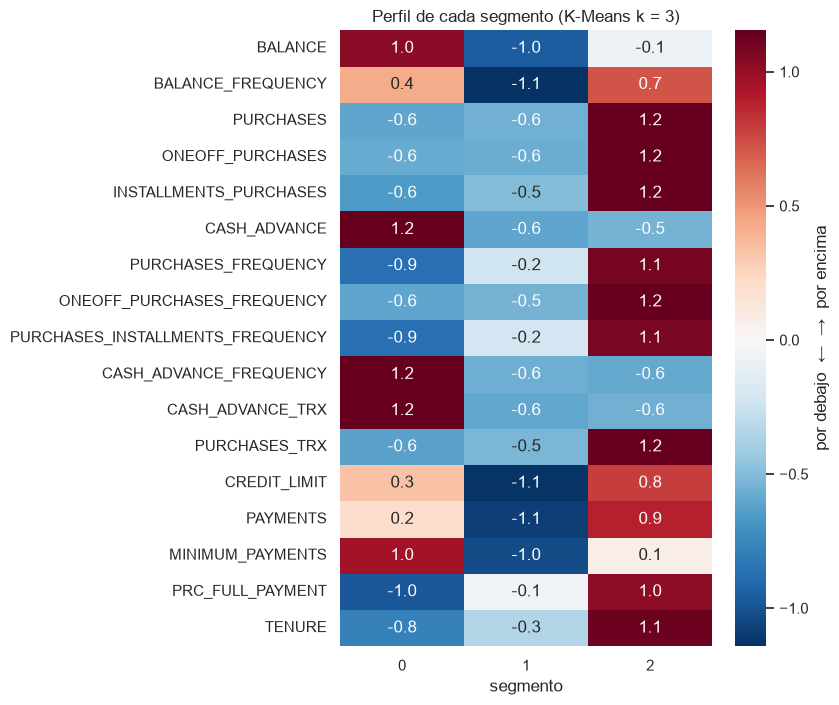

In [7]:
# 3. Estandarizar entre clusters (cada fila: media 0, desviación 1) y pintar el heatmap
z = (medias - medias.mean()) / medias.std()

plt.figure(figsize=(6, 8))
sns.heatmap(z.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar_kws={"label": "por debajo  ←  →  por encima"})
plt.title("Perfil de cada segmento (K-Means k = 3)"); plt.xlabel("segmento"); plt.show()

**Lectura, columna a columna:**

| Segmento | Qué vemos (rojo) | Nombre |
|---|---|---|
| **0** (~18 %) | `CASH_ADVANCE` ~3.900 €, 12 adelantos, mucho `BALANCE` y `MINIMUM_PAYMENTS`; casi nunca paga el total (`PRC_FULL_PAYMENT` ≈ 0) | **Riesgo por adelantos** |
| **1** (~68 %) | Azul en casi todo: poco saldo, poco límite (~3.300 €), pocas compras | **Poco activos** |
| **2** (~14 %) | Compras ~4.300 €, ~57 transacciones, frecuencia de compra 0,9, más límite y paga más el total | **VIP compradores** |

Coincide con la diapositiva: VIP, riesgo y poco activos. Recuerda la **fase 09**: PC1 = **compras** (el brazo VIP) y PC2 = **efectivo** (el brazo de riesgo).

> 📖 **En los libros**
> - **Segundo libro:** «los clusters **no se etiquetan solos**: tienes que hacerlo tú mirando los datos de cada uno». Calcula la **media de cada grupo** (igual que nuestro `groupby().mean()`) y, en otro capítulo, pone nombre a cada grupo mirando sus palabras más frecuentes («Big Data y lenguajes», «Python y estadística»…).
> - **Primer libro:** segmenta a los visitantes de un blog, y salen perfiles como un **40 %** de adolescentes que leen cómics por la tarde y un **20 %** de adultos de ciencia ficción el fin de semana. Es nuestro mismo trabajo: **porcentaje + descripción = segmento**.

### Entregable: nombre y estrategia

| Segmento | Estrategia de marketing |
|---|---|
| 💎 **VIP compradores** | Fidelizar: programa de puntos, subir el límite, tarjeta premium |
| ⚠️ **Riesgo por adelantos** | Vigilar el riesgo de impago; ofrecer un préstamo personal más barato que el adelanto; educación financiera |
| 💤 **Poco activos** | Activar: cashback en las primeras compras, recordatorios, ofertas de comercios |

In [8]:
nombres_seg = {0: "Riesgo por adelantos", 1: "Poco activos", 2: "VIP compradores"}
perfil["segmento"] = perfil["cluster"].map(nombres_seg)
perfil["segmento"].value_counts(normalize=True).mul(100).round(1)

segmento
Poco activos            68.3
Riesgo por adelantos    17.9
VIP compradores         13.8
Name: proportion, dtype: float64

## Detección de anomalías (Isolation Forest)

*Recuerda (fase 06):* Isolation Forest **aísla** cada cliente con cortes al azar. Los raros se aíslan con **pocos cortes**. Con `contamination=0.05` le pedimos que marque el **5 % más raro**.

Atípicos: 448 (5.0%)


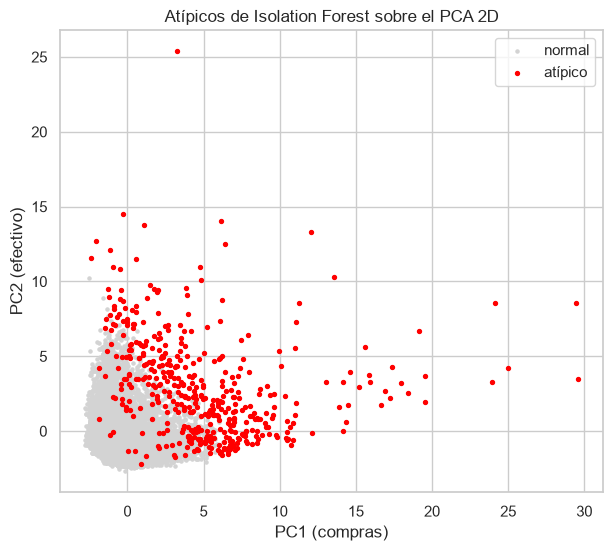

In [9]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
perfil["atipico"] = iso.fit_predict(X) == -1          # -1 = atípico
print("Atípicos:", perfil["atipico"].sum(), f"({perfil['atipico'].mean():.1%})")

plt.figure(figsize=(7, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c="lightgrey", s=5, label="normal")
a = perfil["atipico"].values
plt.scatter(X_pca[a, 0], X_pca[a, 1], c="red", s=8, label="atípico")
plt.xlabel("PC1 (compras)"); plt.ylabel("PC2 (efectivo)"); plt.legend()
plt.title("Atípicos de Isolation Forest sobre el PCA 2D"); plt.show()

Los atípicos (rojo) están en el **borde de la nube y a lo largo de los brazos**: los que más compran (derecha) y los que más efectivo sacan (arriba). En el centro, donde están los poco activos, casi no hay. ¿En qué segmento caen?

In [10]:
# ¿Cuántos atípicos hay en cada segmento? ¿Y cómo son comparados con los normales?
display(pd.crosstab(perfil["segmento"], perfil["atipico"], margins=True))

pd.DataFrame({"mediana atípicos": perfil[perfil["atipico"]].median(numeric_only=True),
              "mediana normales": perfil[~perfil["atipico"]].median(numeric_only=True)}
            ).drop(index=["cluster", "atipico"]).round(1)

atipico,False,True,All
segmento,,,
Poco activos,6110,7,6117
Riesgo por adelantos,1438,160,1598
VIP compradores,954,281,1235
All,8502,448,8950


,mediana atípicos,mediana normales
BALANCE,3794.5,817.2
BALANCE_FREQUENCY,1.0,1.0
PURCHASES,4884.8,329.9
ONEOFF_PURCHASES,2643.9,1.7
INSTALLMENTS_PURCHASES,988.1,74.5
CASH_ADVANCE,1643.7,0.0
PURCHASES_FREQUENCY,1.0,0.4
ONEOFF_PURCHASES_FREQUENCY,0.7,0.1
PURCHASES_INSTALLMENTS_FREQUENCY,0.8,0.2
CASH_ADVANCE_FREQUENCY,0.2,0.0


**Lectura:**
- Casi **ningún** atípico es **poco activo**: los atípicos están en **VIP** y en **riesgo**.
- La **mediana** de los atípicos: compras ~4.900 € frente a ~330 €, límite 9.500 € frente a 3.000 €. Son **grandes clientes**, no datos rotos (en la fase 07 no había valores imposibles salvo 8 frecuencias).
- **Atípico ≠ error.** Cada uno hay que **revisarlo**: puede ser un VIP de verdad (cuidarlo), un posible fraude (avisar a seguridad) o un error de datos (corregirlo).

> 📖 **En los libros**
> - **Primer libro:** explica Isolation Forest igual (cortes al azar; las anomalías se aíslan en **menos cortes**). Su primer ejemplo es justo el nuestro: **fraude con tarjetas** (importe, hora, frecuencia, distancia a casa). También un detector de piezas defectuosas que marca el **2 %** más raro: el porcentaje lo **decides tú**, como nuestro `contamination=0.05`.
> - **Segundo libro:** no trata Isolation Forest; busca los raros **a ojo** con gráficos. Encuentra un usuario extremo que era una **cuenta de prueba** olvidada (un **error**, se elimina) y una fecha con el **año 3014** (una errata). Error, fraude o VIP: **hay que investigar cada caso**.

In [11]:
# Los 81 de "ruido" de DBSCAN (fase 10): ¿los ve también Isolation Forest?
ruido_db = clusters_db == -1
print("Ruido DBSCAN:", ruido_db.sum(), "→ de ellos, atípicos para Isolation Forest:", (ruido_db & perfil["atipico"].values).sum())

Ruido DBSCAN: 81 → de ellos, atípicos para Isolation Forest: 80


Dos métodos muy distintos (densidad y cortes al azar) señalan **a los mismos clientes extremos**. Esto confirma lo de la fase 11: DBSCAN aquí **no segmenta**, pero **sí detecta atípicos**.

> **Resumen fase 12:** con el **heatmap de perfiles** (medias por cluster sin escalar, estandarizadas entre clusters) los números se vuelven **negocio**: 💤 **Poco activos** ~68 %, ⚠️ **Riesgo por adelantos** ~18 %, 💎 **VIP compradores** ~14 %, cada uno con su **estrategia**. **Isolation Forest** marca un 5 % de atípicos, casi todos **VIP o riesgo**: no son errores, son clientes para **revisar uno a uno**.